# 02 — Agregação semanal e recorte das séries

Etapas 2 e 3 da Fase 1 (`docs/PLANO_ML.md`). Toda a lógica está em `src/pipeline/weekly.py`; aqui se confere e se decide.

**Decisão de semana:** segunda a domingo, rotulada pela segunda-feira. Vendas são variável de fluxo: a semana é a **soma** dos dias.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.2f}".format

from pipeline.config import SELECTED_SERIES
from pipeline.data import load_stores, load_train
from pipeline.weekly import complete_weeks, select_series, to_weekly

daily = load_train()
stores = load_stores()
weekly = to_weekly(daily)
first, last = complete_weeks(daily["date"])
print(f"semanas completas: {weekly.week_start.nunique()} ({first.date()} a {last.date()} + 6 dias)")
weekly.head()

semanas completas: 240 (2013-01-07 a 2017-08-07 + 6 dias)


,store_nbr,family,week_start,sales,onpromotion,n_days
0,1,AUTOMOTIVE,2013-01-07,13.00,0,7
1,1,AUTOMOTIVE,2013-01-14,13.00,0,7
2,1,AUTOMOTIVE,2013-01-21,16.00,0,7
3,1,AUTOMOTIVE,2013-01-28,14.00,0,7
4,1,AUTOMOTIVE,2013-02-04,14.00,0,7


## 1. Conferências da Etapa 2

As mesmas que os testes em `tests/pipeline/test_weekly.py` automatizam:
- cada série tem 240 linhas, sem `NaN`;
- a soma semanal bate com a diária no mesmo intervalo;
- `n_days` é 7 em todas as semanas, exceto 6 nas quatro semanas de Natal (25/12 não tem linha).

In [2]:
sizes = weekly.groupby(["store_nbr", "family"], observed=True).size()
inside = daily[(daily.date >= first) & (daily.date <= last + pd.Timedelta(days=6))]
short = sorted(weekly.loc[weekly.n_days != 7, "week_start"].dt.strftime("%Y-%m-%d").unique())
print("linhas por série:", sizes.unique(), "| NaN:", int(weekly[["sales", "n_days"]].isna().sum().sum()))
print(f"soma semanal {weekly.sales.sum():,.0f} × diária {inside.sales.sum():,.0f}")
print("semanas com 6 dias:", short)

linhas por série: [240] | NaN: 0
soma semanal 1,069,909,797 × diária 1,069,909,797
semanas com 6 dias: ['2013-12-23', '2014-12-22', '2015-12-21', '2016-12-19']


## 2. O que a agregação compra e o que custa

A semana elimina o padrão de dia da semana e boa parte dos zeros. Em troca, apaga o perfil dentro da semana, que a Fase 3 recupera.

zeros: 31.3% das linhas diárias × 25.1% das semanais


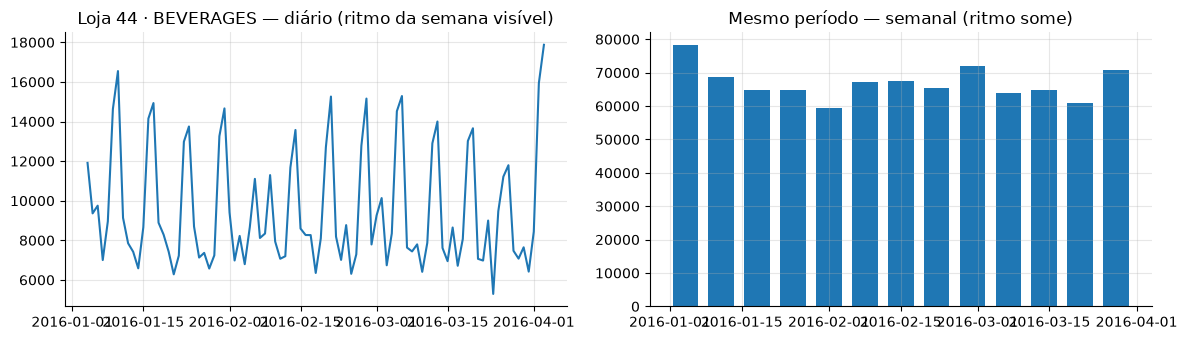

In [3]:
zeros_daily = (daily.sales == 0).mean()
zeros_weekly = (weekly.sales == 0).mean()
print(f"zeros: {zeros_daily:.1%} das linhas diárias × {zeros_weekly:.1%} das semanais")
ex = daily[(daily.store_nbr == 44) & (daily.family == "BEVERAGES") & (daily.date >= "2016-01-04") & (daily.date < "2016-04-04")]
exw = weekly[(weekly.store_nbr == 44) & (weekly.family == "BEVERAGES") & (weekly.week_start >= "2016-01-04") & (weekly.week_start < "2016-04-04")]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(ex.date, ex.sales); ax[0].set_title("Loja 44 · BEVERAGES — diário (ritmo da semana visível)")
ax[1].bar(exw.week_start, exw.sales, width=5); ax[1].set_title("Mesmo período — semanal (ritmo some)")
plt.tight_layout(); plt.show()

## 3. Recorte (Etapa 3): critérios declarados antes de olhar qualquer erro

1. Histórico completo: vende desde jan/2013 e não tem semana zerada.
2. Diversidade: uma loja grande (44, Quito, tipo A) e uma pequena (54, El Carmen, tipo C); famílias perecíveis e não perecíveis, estáveis e voláteis.
3. Famílias com equivalente direto nas categorias do app (pensando na Fase 7).

In [4]:
g = weekly.groupby(["store_nbr", "family"], observed=True).sales
summary = pd.DataFrame({"media_semanal": g.mean(), "cv": g.std() / g.mean(), "semanas_zeradas": g.apply(lambda s: int((s == 0).sum()))}).reset_index()
summary = summary.merge(stores[["store_nbr", "city", "type"]], on="store_nbr")
keys = pd.DataFrame(SELECTED_SERIES, columns=["store_nbr", "family"])
chosen = summary.merge(keys, on=["store_nbr", "family"])
print(f"séries sem semana zerada: {(summary.semanas_zeradas == 0).sum()} de {len(summary)}")
chosen.sort_values(["store_nbr", "family"])

séries sem semana zerada: 711 de 1782


,store_nbr,family,media_semanal,cv,semanas_zeradas,city,type
0,44,BEVERAGES,"55,731.22",0.36,0,Quito,A
1,44,BREAD/BAKERY,"9,682.26",0.21,0,Quito,A
2,44,DAIRY,"17,767.14",0.19,0,Quito,A
3,44,GROCERY I,"68,005.27",0.19,0,Quito,A
4,54,BEVERAGES,"8,970.52",0.61,0,El Carmen,C
5,54,BREAD/BAKERY,"1,526.53",0.14,0,El Carmen,C
6,54,DAIRY,"1,260.60",0.44,0,El Carmen,C
7,54,GROCERY I,"18,466.84",0.20,0,El Carmen,C


In [5]:
cand = summary[summary.family.isin(["PRODUCE", "HOME CARE"]) & summary.store_nbr.isin([44, 54])]
print("Evitadas (PRODUCE tem semanas zeradas por falha de registro; HOME CARE sem histórico completo):")
cand

Evitadas (PRODUCE tem semanas zeradas por falha de registro; HOME CARE sem histórico completo):


,store_nbr,family,media_semanal,cv,semanas_zeradas,city,type
1437,44,HOME CARE,"2,796.21",0.81,87,Quito,A
1449,44,PRODUCE,"44,375.35",0.80,9,Quito,A
1767,54,HOME CARE,933.74,0.78,87,El Carmen,C
1779,54,PRODUCE,"2,477.83",0.82,91,El Carmen,C


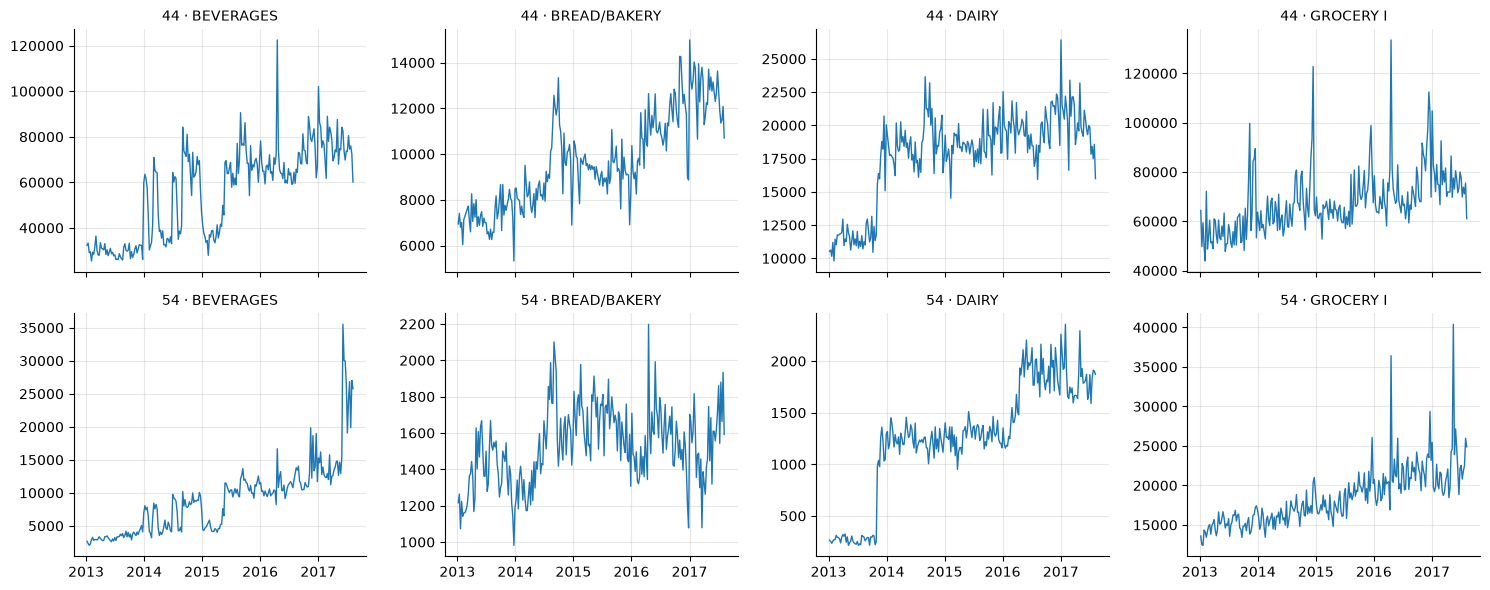

recorte: 1920 linhas = 8 séries × 240 semanas


In [6]:
sel = select_series(weekly, SELECTED_SERIES)
assert len(sel) == len(SELECTED_SERIES) * 240
fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharex=True)
for ax, (key, s) in zip(axes.flat, sel.groupby(["store_nbr", "family"], observed=True)):
    ax.plot(s.week_start, s.sales, lw=1); ax.set_title(f"{key[0]} · {key[1]}", fontsize=10)
plt.tight_layout(); plt.show()
print(f"recorte: {len(sel)} linhas = {len(SELECTED_SERIES)} séries × 240 semanas")

**Viés de seleção (limitação declarada):** séries limpas e volumosas fazem o erro parecer menor do que seria no catálogo inteiro. Por isso o modelo do app (Fase 2) é avaliado em **todas** as 1.729 séries, por faixa de volume.